In [ ]:
!pip install

In [3]:
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# Path lokasi file data
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Data Sentimen/hasil_komentar.csv")
df.head()

,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,...,Unnamed: 5,Rudiyanto_zh,in,Indonesia,0.1,1,0.2,https://x.com/Cak_N0er/status/1859457536837198178,1339291068,Cak_N0er
0,1.871698e+18,Wed Dec 25 13:41:53 +0000 2024,0.0,@FayaAtika @paulus_pebria @prabowo Lumayan laa...,1.871914e+18,NaN,FayaAtika,in,"Kalimantan Barat, Indonesia",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,Rudiyanto_zh,in,Depan 3 Monitor,0.0,1.0,0.0,https://x.com/mbangunCom/status/18593852498280...,2.889534e+09,mbangunCom
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,Rudiyanto_zh,in,Jakarta Capital Region,0.0,1.0,0.0,https://x.com/IdSentra/status/1859251178984657189,3.845937e+09,IdSentra
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,Rudiyanto_zh,in,NaN,0.0,0.0,0.0,https://x.com/Alfamaulana01/status/18597051460...,2.345861e+08,Alfamaulana01
4,1.745646e+18,Sun Jan 14 17:41:37 +0000 2024,0.0,@triwul82 that's so good to me,1.746588e+18,NaN,triwul82,en,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Ambil beberapa atribut
df = df[['full_text', 'username', 'created_at']]
df

,full_text,username,created_at
0,@FayaAtika @paulus_pebria @prabowo Lumayan laa...,zulhusaini133,Wed Dec 25 13:41:53 +0000 2024
1,NaN,NaN,NaN
2,NaN,NaN,NaN
3,NaN,NaN,NaN
4,@triwul82 that's so good to me,TobyWood46,Sun Jan 14 17:41:37 +0000 2024
...,...,...,...
874,@harkatmartabak Mantul pak,Babahireng2,Sat Dec 07 04:18:07 +0000 2024
875,@harkatmartabak Utang UMKM sudah di hapus,laura6_3,Sat Dec 07 02:58:55 +0000 2024
876,@BennyValentinus Wkwkwk,budihandi17,Tue Jan 30 23:15:30 +0000 2024
877,@BennyValentinus Maklumlah opa2 otak lamban br...,panjianom102,Wed Jan 31 00:41:18 +0000 2024


1. Cleaning Data

In [ ]:
# Melihat Baris dan Kolom Data Mentah
df.shape

(879, 3)

In [ ]:
# Hapus Duplicate/Atribut yang memiliki Nilai yang sama
df = df.drop_duplicates(subset='full_text')

In [ ]:
# Cek apakah masih ada data yang duplikat
df.duplicated().sum()

0

In [ ]:
# Hapus Nilai yang Kosong
df = df.dropna()

In [ ]:
# Cek apakah ada variabel yang kosong
df.isnull().sum()

,0
full_text,0
username,0
created_at,0


In [ ]:
# Hapus Duplicate dan Nilai Kosong
df = df.drop_duplicates(subset='full_text')
df = df.dropna()

# Cek hasil Cleaning
df.shape

(778, 3)

In [ ]:
# Buat Function untuk pembersihan
def clean_twitter_text(text):
  text = re.sub(r'@[A-Za-z0-9_]+', '', text)  # Hapus Mention
  text = re.sub(r'#\w+', '', text)            # Hapus Hastag
  text = re.sub(r'RT[\s]+', '', text)         # Hapus Repeat
  text = re.sub(r'https?://\S+', '', text)    # Hapus URL

  text = re.sub(r'[^A-Za-z0-9 ]', '', text)   # Hapus Character Non-Alphanumeric
  text = re.sub(r'\s+', ' ', text).strip()    # Hapus Spasi lebih dari satu

  return text

df['full_text'] = df['full_text'].apply(clean_twitter_text)

In [ ]:
# Ubah data jadi Huruf kecil
df['full_text'] = df['full_text'].str.lower()

In [ ]:
# Tampilkan Data
df

,full_text,username,created_at
0,lumayan laa biar mereka ngak terlalu terbebani,zulhusaini133,Wed Dec 25 13:41:53 +0000 2024
4,thats so good to me,TobyWood46,Sun Jan 14 17:41:37 +0000 2024
5,its so cool,puionacinta_,Sun Jan 14 17:41:39 +0000 2024
24,s dan k berlaku,massukis17,Wed Nov 06 12:05:03 +0000 2024
25,yang gak punya hutang pasti nyesel yu ramerame...,Idiand,Thu Oct 24 12:01:16 +0000 2024
...,...,...,...
871,hoax,loka_griya,Sun Dec 08 21:10:00 +0000 2024
872,semoga umkm bisa berkiprah tanpa beban utang,AdiwarnaSa56658,Sat Dec 07 16:01:46 +0000 2024
873,ngiseeenk,gondes9119,Sun Dec 08 18:16:41 +0000 2024
874,mantul pak,Babahireng2,Sat Dec 07 04:18:07 +0000 2024


2. Preprocessing
  - Normalisasi
  - Stopword
  - Tokenize
  - Stemming

In [ ]:
norm = {
    " yg ": " yang ",
    " jg ": " juga ",
    " biar ": " agar ",
    "nggak": " tidak ",
    " gak ": " tidak ",
    " ngak ": " tidak ",
    " jgn ": " jangan ",
    " jgn2 ": " jangan-jangan ",
    " dinegeri ": " di negeri ",
    " cuma ": " hanya ",
    " cuman ": " hanya ",
    " buat ": " untuk ",
    " bat ": " banget ",
    " butuh ": " membutuhkan ",
    " gpp ": " tidak apa apa ",
    " ga ": " tidak ",
    " tdk ": " tidak ",
    " ngga ": " tidak ",
    " dgn ": " dengan ",
    " u ": " anda ",
    " utk ": " untuk ",
    " pdhl ": " padahal ",
    " pd ": " pada ",
    " ttg ": " tentang ",
    " krn ": " karena ",
    " jd ": " jadi ",
    " sdh ": " sudah ",
    " blm ": " belum ",
    " byk ": " banyak ",
    " bgt ": " banget ",
    " lol ": " tertawa terbahak-bahak ",
    " wkwk ": " tertawa ",
    " haha ": " tertawa ",
    " hehehe ": " tertawa ",
    " manfaatin ": " manfaatkan ",
    " betul ": " benar ",
    " doang ": " saja ",
    " dr ": " dari ",
    " sm ": " sama ",
    " aj ": " saja ",
    " trs ": " terus ",
    " tp ": " tapi ",
    " trus ": " terus ",
    " hrs ": " harus ",
    " hrsnya ": " seharusnya ",
    " klo ": " kalau ",
    " kl ": " kalau ",
    " kalo ": " kalau ",
    " org ": " orang ",
    " spt ": " seperti ",
    " lg ": " lagi ",
    " knp ": " kenapa ",
    " kmrn ": " kemarin ",
    " msh ": " masih ",
    " skrg ": " sekarang ",
    " blom ": " belum ",
    " blum ": " belum ",
    " ampe ": " sampai ",
    " pake ": " pakai ",
    " jdlnya ": " jadinya ",
    " disini ": " di sini ",
    " disana ": " di sana ",
    " dimana ": " di mana ",
    " tsb ": " tersebut ",
    " oke ": " baik ",
    " sbg ": " sebagai ",
    " nyoba ": " mencoba ",
    " pgn ": " ingin ",
    " dmn ": " di mana ",
    " ribet ": " rumit ",
    " capek ": " lelah ",
    " susah ": " sulit ",
    " percuma ": " sia-sia ",
    " bingung ": " kebingungan ",
    " lho ": " loh ",
    " tetep ": " tetap ",
    " salut ": " salut ",
    " guys ": " teman-teman ",
    " bayar ": " membayar ",
    " dong ": " tolong ",
    " skip ": " lewati ",
    " malah ": " bahkan ",
    " eligible ": " memenuhi syarat ",
    " kelilit ": " terjebak ",
    " lo ": " kamu ",
    " lunasin ": " lunaskan ",
    " sampe ": " sampai ",
    " yes ": " ya ",
    " plis ": " tolong ",
    " lu ": " kamu ",
    " ambil ": " ambil ",
    " btw ": " omong-omong ",
    " asap ": " secepat mungkin ",
    " ok ": " baik ",
    " no ": " tidak ",
    " donk ": " dong ",
    " d ": " di ",
    " aku ": " saya ",
    " acc ": " disetujui ",
    " ayo ": " mari ",
    " mantep ": " mantap ",
    " mantul ": " mantap ",
    " mantaap ": " mantap ",
    " makanya ": " oleh karena itu ",
    " nurut ": " patuh ",
    " terfavorit ": " paling disukai ",
    " struggling ": " berjuang ",
    " strugling ": " berjuang ",
    " struggle ": " berjuang ",
    " disamain ": " di samakan ",
    " tani ": " petani ",
    " makin ": " semakin ",
    " lilit ": " terlilit ",
    " snk ": " syarat dan ketentuan ",
    " tuju ": " setuju ",
    "tuju ": " setuju ",
    " ilang ": " hilang ",
    " smpai ": " sampai ",
    " inget ": " ingat ",
    " gas aja ": " langsung saja ",
    " dpet ": " dapat ",
    " kelaz ": " bagus ",
    " henti ": " berhenti ",
    " gimana ": " bagaimana ",
    " emang ": " memang ",
    " sasar ": " sasaran ",
    " gw ": " saya ",
    " gue ": " saya ",
    " tuju ": " setuju ",
    " yaa ": " ya ",
    " yah ": " ya ",
    " yuk ": " mari ",
    " coy ": " teman ",
    " bener2 ": " benar benar ",
    " bener ": " benar ",
    " juang ": " perjuangan ",
    " ngeringanin ": " meringankan ",
    " hutang ": " utang ",
    " nyesel ": " menyesal ",
    " rame-rame ": " ramai ramai ",
    "  yu ": " yuk ",
    " pinjem ": " pinjam ",
    " duit ": " uang ",
    " jng ": " jangan ",
    " drama2 ": " drama drama ",
    " sprti ": " seperti ",
    " sekrang ": " sekarang ",
    " ngutang ": " berhutang ",
    " sy ": " saya ",
    " nanem ": " menanam ",
    " lunasin ": " lunaskan ",
    " masak ": " masa ",
    " pinjol ": " pinjaman online ",
    " penerimah ": " penerima ",
    " lbh ": " lebih ",
    " omon omon ": " sekadar omongan kosong ",
    " tuh kan ": " lihatlah ",
    " tuuh ": " lihatlah ",
    " klu ": " kalau ",
    " bln ": " bulan ",
    " anjayyyy ": " luar biasa ",
    " anjayyy ": " luar biasa ",
    " anjayy ": " luar biasa ",
    " anjay ": " luar biasa ",
    " wlau ": " walau ",
    " komitment ": " komitmen ",
    " spt ": " seperti ",
    " aq ": " saya ",
    " krn ": " karena ",
    " gk ": " tidak ",
    " bs ": " bisa ",
    " biasane ": " biasanya ",
    " ono ": " ada ",
    " nang ": " di ",
    " apik ": " apik ",
    " manut ": " nurut ",
    " ojol ": " ojek online ",
    " dpt ": " dapat ",
    " pmth ": " pemerintah ",
    " cm ": " hanya ",
    " tlg ": " tolong ",
    " ut ": " untuk ",
    " ttp ": " tetap ",
    " dengar2 ": " berdasarkan kabar yang beredar ",
    " min ": " admin ",
    " nyalon ": " mencalonkan ",
    " ngapain ": " mengapa ",
    " bapak2 ": " bapak-bapak ",
    " pungli ": " pemungutan liar ",
    " pungli2 ": " pemungutan liar ",
    " gr ": " gara-gara ",
    " gr2 ": " gara-gara ",
    " karepmu ": " tarserahmu ",
    " gini ": " seperti ini ",
    " kpd ": " kepada ",
    " lainya ": " lainnya ",
    " wong ": " orang ",
    " byr ": " bayar ",
    " nti ": " nanti ",
    " nnti ": " nanti ",
    " bkn ": " bukan ",
    " koq ": " kok ",
    " d ": " di ",
    " anteng2 ": " tenang ",
    " anteng ": " tenang ",
    " jls ": " jelas ",
    " s dan k ": " syarat dan ketentuan ",
    " hal2 ": " hal-hal ",
    " dlm ": " dalam ",
    " gmn ": " bagaimana ",
    " kpn ": " kapan "
}

import re

# Fungsi normalisasi
def normalisasi(str_text):
    for key, value in norm.items():
        # Gunakan regex untuk pencocokan kata utuh
        str_text = re.sub(rf'\b{re.escape(key.strip())}\b', value.strip(), str_text)
    return str_text

# Terapkan fungsi ke kolom 'full_text'
df['full_text'] = df['full_text'].apply(normalisasi)
df


,full_text,username,created_at
0,lumayan laa agar mereka tidak terlalu terbebani,zulhusaini133,Wed Dec 25 13:41:53 +0000 2024
4,thats so good to me,TobyWood46,Sun Jan 14 17:41:37 +0000 2024
5,its so cool,puionacinta_,Sun Jan 14 17:41:39 +0000 2024
24,syarat dan ketentuan berlaku,massukis17,Wed Nov 06 12:05:03 +0000 2024
25,yang tidak punya utang pasti menyesal mari ram...,Idiand,Thu Oct 24 12:01:16 +0000 2024
...,...,...,...
871,hoax,loka_griya,Sun Dec 08 21:10:00 +0000 2024
872,semoga umkm bisa berkiprah tanpa beban utang,AdiwarnaSa56658,Sat Dec 07 16:01:46 +0000 2024
873,ngiseeenk,gondes9119,Sun Dec 08 18:16:41 +0000 2024
874,mantap pak,Babahireng2,Sat Dec 07 04:18:07 +0000 2024


In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.6 MB/s eta 0:00:00


In [ ]:
# Stopword
import Sastrawi
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory, StopWordRemover, ArrayDictionary
#more_stop_words = ["tidak"]

stop_words = StopWordRemoverFactory().get_stop_words()
#stop_words.extend(more_stop_words)

new_array = ArrayDictionary(stop_words)
stop_words_remover_new = StopWordRemover(new_array)

def stopword(str_text):
  str_text = stop_words_remover_new.remove(str_text)
  return str_text

df['full_text'] = df['full_text'].apply(lambda x: stopword(x))
df.head()

,full_text,username,created_at
0,lumayan laa mereka terlalu terbebani,zulhusaini133,Wed Dec 25 13:41:53 +0000 2024
4,thats so good to me,TobyWood46,Sun Jan 14 17:41:37 +0000 2024
5,its so cool,puionacinta_,Sun Jan 14 17:41:39 +0000 2024
24,syarat ketentuan berlaku,massukis17,Wed Nov 06 12:05:03 +0000 2024
25,tidak punya utang menyesal ramerame pinjam uang,Idiand,Thu Oct 24 12:01:16 +0000 2024


In [ ]:
#Tokenize
tokenized = df['full_text'].apply(lambda x: x.split())
tokenized

,full_text
0,"[lumayan, laa, mereka, terlalu, terbebani]"
4,"[thats, so, good, to, me]"
5,"[its, so, cool]"
24,"[syarat, ketentuan, berlaku]"
25,"[tidak, punya, utang, menyesal, ramerame, pinj..."
...,...
871,[hoax]
872,"[semoga, umkm, berkiprah, beban, utang]"
873,[ngiseeenk]
874,"[mantap, pak]"


In [ ]:
# Stemming (memerlukan waktu cukup lama)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

def stemming(text_cleaning):
  factory = StemmerFactory()
  stemmer = factory.create_stemmer()
  do = []
  for w in text_cleaning:
    dt = stemmer.stem(w)
    do.append(dt)
  d_clean = []
  d_clean = " ".join(do)
  print(d_clean)
  return d_clean

tokenized = tokenized.apply(stemming)

tokenized.to_csv("/content/drive/MyDrive/Colab Notebooks/hasilPreprocessing/hasilPreprocessing.csv", index=False)
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/hasilPreprocessing/hasilPreprocessing.csv", encoding='latin1')

lumayan laa mereka terlalu beban
thats so good to me
its so cool
syarat tentu laku
tidak punya utang sesal ramerame pinjam uang
kredit pns di putih kan semua saya belanja pasar sedikit baik
pak hasyim kapasitas apa yajubir
selamat tani
kalau ternak
syukur sangat tuju
bukti pihak rakyat kecil setia dukung ganjar
iya program jelas bagus setia dukung ganjar
aduh pak jangan dipitihkan hutang
padahal tani lebih perlu sedia pupuk murah kontinu plus irigasi nelayan perlu bahan bakar murah ekosistem laut sehat bukan sedimen terumbu karang rusak
mantap terimakasih pak presiden
mantap 10 tahun rakyat tipu buang waktu pimpin rezim hanya drama drama presiden harus ini
mulai sekarang rame rame jadi tani nelayan utang lunas hihi
juga tani rumah tanam bawang daun 1 pot lunas paylater
nanti putih utang tani sawit juta hektar wkwkwkwk
janji kampanye ganjarmahfud harus utama janji sendiri dulu waktu kampanye misal bangun 300 fakultas kedokteranambil ide orang bangun citra sendiri nyebelin sih
sesal tida

3. Translate

In [ ]:
!pip install translate

In [6]:
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/hasilPreprocessing/hasilPreprocessing.csv", encoding='latin1')
data.head()

,full_text
0,lumayan laa mereka terlalu beban
1,thats so good to me
2,its so cool
3,syarat tentu laku
4,tidak punya utang sesal ramerame pinjam uang


In [ ]:
# Limit
from translate import Translator
import pandas as pd

# Fungsi untuk menerjemahkan tweet
def convert_eng(tweet):
    try:
        translator = Translator(from_lang="id", to_lang="en")
        translation = translator.translate(tweet)
        return translation
    except Exception as e:
        print(f"Error translating tweet: {tweet}, error: {e}")
        return tweet  # Kembalikan tweet asli jika gagal diterjemahkan

# Pastikan kolom 'full_text' ada dan bersih
if 'full_text' in data.columns:
    # Ganti nilai NaN dengan string kosong
    data['full_text'] = data['full_text'].fillna("")

    # Pastikan semua nilai adalah string
    data['full_text'] = data['full_text'].astype(str)

    # Menambahkan kolom baru dengan hasil terjemahan
    data['tweet_english'] = data['full_text'].apply(convert_eng)

    # Menyimpan hasil ke CSV
    output_path = "/content/drive/MyDrive/Colab Notebooks/hasilTerjemahan/hasilTerjemahan.csv"
    data.to_csv(output_path, index=False)
    print(f"Translation saved to {output_path}")
else:
    print("Column 'full_text' not found in the dataset!")


NameError: name 'data' is not defined

In [7]:
pip install googletrans==4.0.0rc1

In [8]:
from googletrans import Translator
import pandas as pd

# Baca file CSV hasil preprocessing
file_path = "/content/drive/MyDrive/Colab Notebooks/hasilPreprocessing/hasilPreprocessing.csv"
data = pd.read_csv(file_path, encoding='latin1')

# Lihat beberapa data awal untuk memastikan file terbaca
print("Data awal:")
print(data.head())

# Inisialisasi Translator
translator = Translator()

# Fungsi untuk menerjemahkan tweet
def convert_eng(tweet):
    try:
        # Pastikan tweet bukan None atau kosong
        if tweet is None or tweet.strip() == "":
            return ""  # Jika kosong, kembalikan string kosong

        # Terjemahkan teks ke Bahasa Inggris
        translation = translator.translate(tweet, src="id", dest="en")
        return translation.text
    except Exception as e:
        print(f"Error translating tweet: {tweet}, error: {e}")
        return tweet  # Kembalikan tweet asli jika gagal diterjemahkan

# Pastikan kolom 'full_text' ada dan bersih
if 'full_text' in data.columns:
    # Ganti nilai NaN dengan string kosong
    data['full_text'] = data['full_text'].fillna("")

    # Pastikan semua nilai adalah string
    data['full_text'] = data['full_text'].astype(str)

    # Menambahkan kolom baru dengan hasil terjemahan
    data['tweet_english'] = data['full_text'].apply(convert_eng)

    # Menyimpan hasil ke CSV
    output_path = "/content/drive/MyDrive/Colab Notebooks/hasilTerjemahan/hasilTerjemahan.csv"
    data.to_csv(output_path, index=False)
    print(f"Translation saved to {output_path}")
else:
    print("Column 'full_text' not found in the dataset!")


Data awal:
                                      full_text
0              lumayan laa mereka terlalu beban
1                           thats so good to me
2                                   its so cool
3                             syarat tentu laku
4  tidak punya utang sesal ramerame pinjam uang


KeyboardInterrupt: 

4. Labeling

In [6]:
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/hasilTerjemahan/hasilTerjemahan.csv", index_col=0)
data

,tweet_english
full_text,
lumayan laa mereka terlalu beban,pretty good they are too burden
thats so good to me,THATS SO GOOD TO ME
its so cool,its so cool
syarat tentu laku,Conditions of course sell
tidak punya utang sesal ramerame pinjam uang,do not have a debt regret for borrowing money
...,...
hoax,Hoax
moga umkm kiprah beban utang,I hope the UMKM is a debt burden
ngiseeenk,ngiseeenk


In [7]:
!pip install tweet-preprocessor
!pip install textblob
!pip install wordcloud
!pip install nltk

In [8]:
import preprocessor as p
from textblob import TextBlob
import nltk
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [9]:
from textblob import TextBlob

# Proses Labeling
data_tweet = list(data['tweet_english'])
polaritas = 0

status = []
total_positif = total_negatif = total_netral = total = 0

for i, tweet in enumerate(data_tweet):
    # Pastikan tweet adalah string
    if not isinstance(tweet, str):
        tweet = str(tweet)  # Mengonversi tweet menjadi string jika bukan

    # Analisis sentimen dengan TextBlob
    analysis = TextBlob(tweet)
    polaritas += analysis.polarity

    if analysis.sentiment.polarity > 0.0:
        total_positif += 1
        status.append('Positif')
    elif analysis.sentiment.polarity == 0.0:
        total_netral += 1
        status.append('Netral')
    else:
        total_negatif += 1
        status.append('Negatif')

    total += 1

print(f'Hasil Analisis Data:\nPositif = {total_positif}\nNetral = {total_netral}\nNegatif = {total_negatif}')
print(f'\nTotal Data = {total}')


Hasil Analisis Data:
Positif = 369
Netral = 317
Negatif = 92

Total Data = 778


In [10]:
# Tampilkan Data setelah Klasifikasi menggunakan TextBlob
data['klasifikasi'] = status
data

,tweet_english,klasifikasi
full_text,,
lumayan laa mereka terlalu beban,pretty good they are too burden,Positif
thats so good to me,THATS SO GOOD TO ME,Positif
its so cool,its so cool,Positif
syarat tentu laku,Conditions of course sell,Netral
tidak punya utang sesal ramerame pinjam uang,do not have a debt regret for borrowing money,Netral
...,...,...
hoax,Hoax,Netral
moga umkm kiprah beban utang,I hope the UMKM is a debt burden,Netral
ngiseeenk,ngiseeenk,Netral


5. Visualisasi

In [11]:
# Cek kolom yang ada dalam DataFrame
print(data.columns)


Index(['tweet_english', 'klasifikasi'], dtype='object')


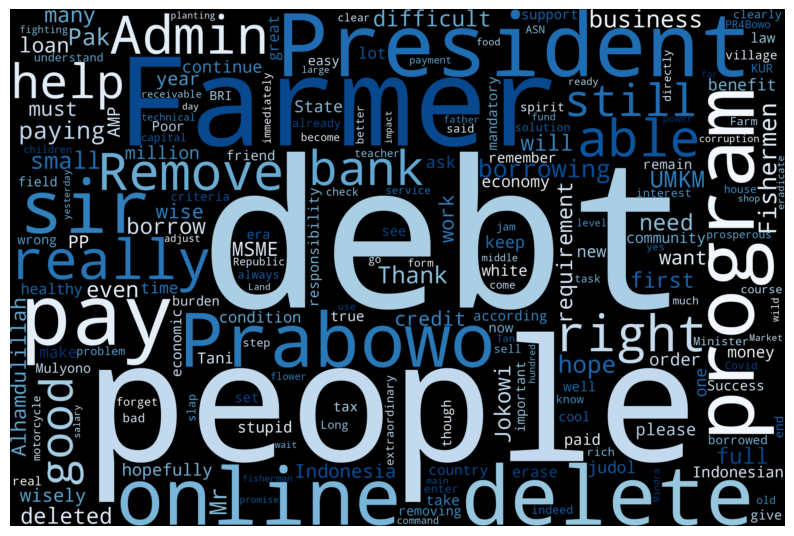

In [12]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

def plot_cloud(wordcloud):
    plt.figure(figsize=(10, 8))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

# Pastikan setiap tweet adalah string dan menangani nilai NaN
all_words = ' '.join([str(tweets) if isinstance(tweets, str) else "" for tweets in data['tweet_english']])

wordcloud = WordCloud(
    width=3000,
    height=2000,
    background_color='black',
    colormap='Blues_r',
    collocations=False,
    stopwords=STOPWORDS
).generate(all_words)

plot_cloud(wordcloud)


Navbar HTML berhasil disimpan di: /content/drive/MyDrive/Colab Notebooks/hasil_visualisasi/navbar.html


In [64]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
import base64
from io import BytesIO

def save_wordcloud_to_html(data, html_path):
    try:
        # Membuat WordCloud
        all_words = ' '.join([str(tweets) if isinstance(tweets, str) else "" for tweets in data['tweet_english']])
        wordcloud = WordCloud(
            width=1000, height=600,
            background_color='black',
            colormap='Blues_r',
            collocations=False,
            stopwords=STOPWORDS
        ).generate(all_words)

        # Simpan WordCloud sebagai gambar sementara di memori
        buffer = BytesIO()
        plt.figure(figsize=(8, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis("off")
        plt.savefig(buffer, format='png')
        plt.close()
        buffer.seek(0)

        # Encode gambar ke dalam format base64
        wordcloud_base64 = base64.b64encode(buffer.getvalue()).decode()

        # Buat file HTML dengan gambar dan tombol navigasi
        with open(html_path, "w") as f:
            f.write(f"""
            <html>
            <head>
                <title>WordCloud</title>
                <style>
                    body {{ font-family: Arial, sans-serif; text-align: center; background-color: #f9f9f9; margin: 0; padding: 20px; }}
                    h2 {{ margin-bottom: 10px; color: #333; }}
                    img {{ margin-top: 10px; max-width: 90%; height: auto; border: 1px solid #ccc; box-shadow: 2px 2px 8px rgba(0,0,0,0.1); }}
                    .bubble-container {{ margin-top: 40px; display: flex; justify-content: center; gap: 15px; }}
                    .bubble {{ width: 130px; height: 50px; border-radius: 25px; background-color: white; box-shadow: 0px 4px 6px rgba(0,0,0,0.2); display: flex; justify-content: center; align-items: center; font-size: 14px; font-weight: bold; color: #333; text-decoration: none; transition: all 0.3s ease; }}
                    .bubble:hover {{ background-color: #e0f7fa; color: #00796b; }}
                    .bubble.active {{ background-color: #b3e5fc; color: #01579b; box-shadow: 0px 4px 12px rgba(0,0,0,0.3); }}
                </style>
            </head>
            <body>
                <h2>Visualisasi WordCloud</h2>
                <img src="data:image/png;base64,{wordcloud_base64}" alt="WordCloud">

                <div class="bubble-container">
                    <a href="wordcloud_sentimen.html" class="bubble active">WORDCLOUD</a>
                    <a href="bar_chart_sentimen.html" class="bubble">BAR-CHART</a>
                    <a href="ldavis_prepared_3.html" class="bubble">LDA MODEL</a>
                </div>
            </body>
            </html>
            """)

        print(f"WordCloud HTML berhasil disimpan di: {html_path}")
    except Exception as e:
        print(f"Error during WordCloud generation: {e}")

# Path untuk menyimpan WordCloud dalam HTML
wordcloud_html_path = "/content/drive/MyDrive/Colab Notebooks/hasil_visualisasi/wordcloud_sentimen.html"
save_wordcloud_to_html(data, wordcloud_html_path)


WordCloud HTML berhasil disimpan di: /content/drive/MyDrive/Colab Notebooks/hasil_visualisasi/wordcloud_sentimen.html


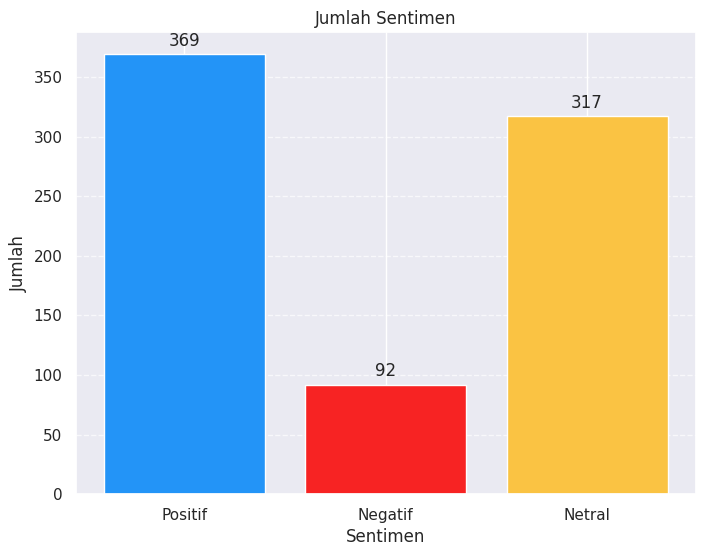

In [14]:
# Tampilkasn Visualisasi Jumlah Sentimen
import seaborn as sns

sns.set_theme()

labels = ['Positif', 'Negatif', 'Netral']
counts = [total_positif, total_negatif, total_netral]

def show_bar_chart(labels, counts, title):
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(labels, counts, color=['#2394f7', '#f72323', '#fac343'])

    for bar, count in zip(bars, counts):
        height = bar.get_height()
        ax.annotate(f'{count}', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

    ax.grid(axis='y', linestyle='--', alpha=0.7)

    ax.set_xlabel('Sentimen')
    ax.set_ylabel('Jumlah')
    ax.set_title(title)

    plt.show()

show_bar_chart(labels, counts, "Jumlah Sentimen")

6. Klasifikasi Sentimen

In [15]:
data

,tweet_english,klasifikasi
full_text,,
lumayan laa mereka terlalu beban,pretty good they are too burden,Positif
thats so good to me,THATS SO GOOD TO ME,Positif
its so cool,its so cool,Positif
syarat tentu laku,Conditions of course sell,Netral
tidak punya utang sesal ramerame pinjam uang,do not have a debt regret for borrowing money,Netral
...,...,...
hoax,Hoax,Netral
moga umkm kiprah beban utang,I hope the UMKM is a debt burden,Netral
ngiseeenk,ngiseeenk,Netral


In [16]:
# Tidak Perlu (Karena Column full_text sudah tidak ada)
#dataset = data.drop(['full_text'], axis=1, inplace=False) # Hapus data full_text
#dataset = [tuple(x) for x in dataset.to_records(index=False)]
#dataset = [tuple(x) for x in data.to_records(index=False)]
dataset = [(str(x[0]), str(x[1])) for x in data[['tweet_english', 'klasifikasi']].values]

# Ensure that the tweet_english column in your DataFrame is of string type:
data['tweet_english'] = data['tweet_english'].astype(str)

In [17]:
# Periksa apakah dataset sudah terisi
print(dataset[:5])  # Cetak beberapa elemen pertama


[('pretty good they are too burden', 'Positif'), ('THATS SO GOOD TO ME', 'Positif'), ('its so cool', 'Positif'), ('Conditions of course sell', 'Netral'), ('do not have a debt regret for borrowing money', 'Netral')]


In [18]:
import random

# Klasifikasi Berdasarkan Naive Bayes Classifier
set_positif = []
set_netral = []
set_negatif = []

# Pisahkan dataset berdasarkan sentimen
for n in dataset:
    if n[1] == 'Positif':
        set_positif.append(n)
    elif n[1] == 'Negatif':
        set_negatif.append(n)
    else:
        set_netral.append(n)

# Ambil sampel secara acak, 50% dari setiap kelompok
set_positif = random.sample(set_positif, k=int(len(set_positif)/2))
set_negatif = random.sample(set_negatif, k=int(len(set_negatif)/2))
set_netral = random.sample(set_netral, k=int(len(set_netral)/2))

# Gabungkan semua data untuk pelatihan
train = set_positif + set_negatif + set_netral

# Membuat train_set
train_set = []

for n in train:
    train_set.append(n)


In [19]:
# Optional
import nltk
nltk.download('punkt')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [20]:
# Optional (untuk cek nltk)
import nltk
print(nltk.data.path)


['/root/nltk_data', '/usr/nltk_data', '/usr/share/nltk_data', '/usr/lib/nltk_data', '/usr/share/nltk_data', '/usr/local/share/nltk_data', '/usr/lib/nltk_data', '/usr/local/lib/nltk_data']


In [21]:
# Optional
import nltk

# Download the 'punkt_tab' resource
nltk.download('punkt_tab')

# Your existing code using word_tokenize goes here
from nltk.tokenize import word_tokenize

text = "This is a sample text."
tokens = word_tokenize(text)
print(tokens)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


['This', 'is', 'a', 'sample', 'text', '.']


In [22]:
from textblob.classifiers import NaiveBayesClassifier
cl = NaiveBayesClassifier(train_set)

# Cetak akurasi menggunakan data pelatihan
print("Akurasi Test: ", cl.accuracy(dataset))

Akurasi Test:  0.7365038560411311


In [23]:
# Labeling
data_tweet = list(data['tweet_english'])
polaritas = 0

status = []
total_positif = total_negatif = total_netral = total = 0

for tweet in data_tweet:
    # Konversi tweet ke string jika bukan string
    if not isinstance(tweet, str):
        tweet = str(tweet)

    # Analisis sentimen menggunakan TextBlob dan classifier
    analysis = TextBlob(tweet, classifier=cl)

    # Tambahkan klasifikasi ke daftar status
    klasifikasi = analysis.classify()
    status.append(klasifikasi)

    # Hitung jumlah tiap sentimen
    if klasifikasi == 'Positif':
        total_positif += 1
    elif klasifikasi == 'Netral':
        total_netral += 1
    elif klasifikasi == 'Negatif':
        total_negatif += 1

    total += 1


print(f'\nHasil Analisis Data:\nPositif = {total_positif}\nNetral = {total_netral}\nNegatif = {total_negatif}')
print(f'\nTotal Data = {total}')



Hasil Analisis Data:
Positif = 326
Netral = 426
Negatif = 26

Total Data = 778


In [24]:
# Cek Panjang Dataframe and Status (Optional)
print(f"Panjang DataFrame: {len(data)}")
print(f"Panjang status: {len(status)}")


Panjang DataFrame: 778
Panjang status: 778


In [25]:
# Optional
while len(status) < len(data):
    status.append(None)  # Menambahkan None atau bisa juga "" untuk elemen yang hilang


In [26]:
# Setelah memastikan panjang status sudah sama dengan panjang data, Anda bisa menambahkan status ke dalam kolom klasifikasi_bayes DataFrame
# Optional
data['klasifikasi_bayes'] = status


In [27]:
# Cek (Optional)
print(data.info())
print(data.head())

<class 'pandas.core.frame.DataFrame'>
Index: 778 entries, lumayan laa mereka terlalu beban to utang umkm di hapus
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   tweet_english      778 non-null    object
 1   klasifikasi        778 non-null    object
 2   klasifikasi_bayes  778 non-null    object
dtypes: object(3)
memory usage: 24.3+ KB
None
                                                                              tweet_english  \
full_text                                                                                     
lumayan laa mereka terlalu beban                            pretty good they are too burden   
thats so good to me                                                     THATS SO GOOD TO ME   
its so cool                                                                     its so cool   
syarat tentu laku                                                 Conditions of course sell   
tid

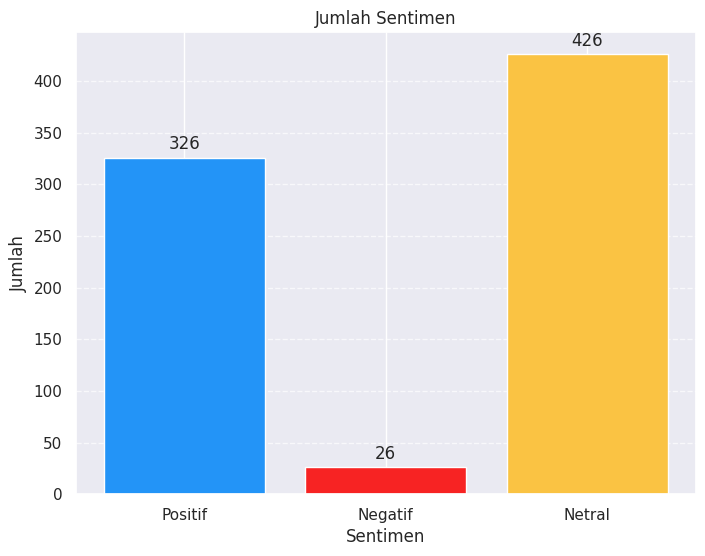

In [28]:
# Tampilkasn Visualisasi Jumlah Sentimen
import matplotlib.pyplot as plt
import seaborn as sns

# Set nama seaborn untuk tampilan yang lebih profesional
sns.set_theme()

labels = ['Positif', 'Negatif', 'Netral']
counts = [total_positif, total_negatif, total_netral]

def show_bar_chart(labels, counts, title):
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(labels, counts, color=['#2394f7', '#f72323', '#fac343'])

    # Menambahkan keterangan presentase
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        ax.annotate(f'{count}', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

    # Menambahkan grid
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Menambahkan label sumbu dan judul
    ax.set_xlabel('Sentimen')
    ax.set_ylabel('Jumlah')
    ax.set_title(title)

    plt.show()

show_bar_chart(labels, counts, "Jumlah Sentimen")

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
import base64
from io import BytesIO

# Fungsi untuk menyimpan diagram batang ke file HTML
def save_bar_chart_with_accuracy_to_html(labels, counts, title, accuracy, html_path):
    # Buat diagram batang
    sns.set_theme()  # Tampilan profesional
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(labels, counts, color=['#2394f7', '#f72323', '#fac343'])

    # Menambahkan keterangan presentase di atas setiap batang
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        ax.annotate(f'{count}', xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # Offset vertikal
                    textcoords="offset points",
                    ha='center', va='bottom')

    # Menambahkan grid dan label
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.set_xlabel('Sentimen')
    ax.set_ylabel('Jumlah')
    ax.set_title(title)

    # Simpan plot ke buffer
    buffer = BytesIO()
    plt.savefig(buffer, format='png', bbox_inches='tight')
    plt.close(fig)
    buffer.seek(0)

    # Encode gambar ke dalam format base64
    bar_chart_base64 = base64.b64encode(buffer.getvalue()).decode()

    # Buat file HTML
    with open(html_path, "w") as f:
        f.write(f"""
        <html>
        <head>
            <title>Diagram Batang Sentimen</title>
            <style>
                body {{ font-family: Arial, sans-serif; text-align: center; background-color: #f9f9f9; margin: 0; padding: 20px; }}
                h2 {{ margin-bottom: 10px; color: #333; }}
                img {{ margin-top: 10px; max-width: 90%; height: auto; border: 1px solid #ccc; box-shadow: 2px 2px 8px rgba(0,0,0,0.1); }}
                p {{ margin-top: 15px; font-size: 14px; color: #555; }}
                .bubble-container {{ margin-top: 40px; display: flex; justify-content: center; gap: 15px; }}
                .bubble {{ width: 130px; height: 50px; border-radius: 25px; background-color: white; box-shadow: 0px 4px 6px rgba(0,0,0,0.2); display: flex; justify-content: center; align-items: center; font-size: 14px; font-weight: bold; color: #333; text-decoration: none; transition: all 0.3s ease; }}
                .bubble:hover {{ background-color: #e0f7fa; color: #00796b; }}
                .bubble.active {{ background-color: #b3e5fc; color: #01579b; box-shadow: 0px 4px 12px rgba(0,0,0,0.3); }}
            </style>
        </head>
        <body>
            <h2>Visualisasi Diagram Batang Sentimen</h2>
            <img src="data:image/png;base64,{bar_chart_base64}" alt="Diagram Batang Sentimen">
            <p>Akurasi Model Naive Bayes: <strong>{accuracy:.2%}</strong></p>

            <div class='bubble-container'>
                <a href='wordcloud_sentimen.html' class='bubble'>WORDCLOUD</a>
                <a href='bar_chart_sentimen.html' class='bubble active'>BAR-CHART</a>
                <a href='ldavis_prepared_3.html' class='bubble'>LDA MODEL</a>
            </div>
        </body>
        </html>
        """)

    print(f"Diagram batang HTML berhasil disimpan di: {html_path}")


# Data sentimen (harus sesuai dengan hasil klasifikasi Naive Bayes)
labels = ['Positif', 'Negatif', 'Netral']
counts = [total_positif, total_negatif, total_netral]  # Gunakan hasil dari Naive Bayes

# Ambil akurasi dari model Naive Bayes
from textblob.classifiers import NaiveBayesClassifier

# Pastikan train_set sudah didefinisikan sebelumnya
cl = NaiveBayesClassifier(train_set)
accuracy = cl.accuracy(dataset)  # Hitung akurasi model

# Path untuk menyimpan HTML
bar_chart_html_path = "/content/drive/MyDrive/Colab Notebooks/hasil_visualisasi/bar_chart_sentimen.html"

# Panggil fungsi untuk menyimpan
save_bar_chart_with_accuracy_to_html(labels, counts, "Jumlah Sentimen", accuracy, bar_chart_html_path)


Diagram batang HTML berhasil disimpan di: /content/drive/MyDrive/Colab Notebooks/hasil_visualisasi/bar_chart_sentimen.html


In [30]:
data

,tweet_english,klasifikasi,klasifikasi_bayes
full_text,,,
lumayan laa mereka terlalu beban,pretty good they are too burden,Positif,Positif
thats so good to me,THATS SO GOOD TO ME,Positif,Netral
its so cool,its so cool,Positif,Netral
syarat tentu laku,Conditions of course sell,Netral,Netral
tidak punya utang sesal ramerame pinjam uang,do not have a debt regret for borrowing money,Netral,Netral
...,...,...,...
hoax,Hoax,Netral,Netral
moga umkm kiprah beban utang,I hope the UMKM is a debt burden,Netral,Netral
ngiseeenk,ngiseeenk,Netral,Netral


In [31]:
data_eval = [tuple(x) for x in data.to_records(index=False)]

for n in data_eval:
    # Mengecek apakah ada nilai pada kolom klasifikasi_bayes (kolom ketiga, indeks 2)
    if len(n) == 3:
        if n[1] != n[2]:  # Memeriksa perbedaan antara klasifikasi dan klasifikasi_bayes
            print(f'Text: {n[0]}\nClassifier: {n[1]}\nClassifier Bayes: {n[2]}\n')
    else:
        print("Tupel tidak memiliki cukup elemen.")


Text: THATS SO GOOD TO ME
Classifier: Positif
Classifier Bayes: Netral

Text: its so cool
Classifier: Positif
Classifier Bayes: Netral

Text: Happy Tani
Classifier: Positif
Classifier Bayes: Netral

Text: Gratitude is very aimed
Classifier: Positif
Classifier Bayes: Netral

Text: great thank you, sir, the president
Classifier: Positif
Classifier Bayes: Netral

Text: good small people just defend Jokowi
Classifier: Positif
Classifier Bayes: Netral

Text: more months of bank news
Classifier: Positif
Classifier Bayes: Netral

Text: number 3 is quite easy
Classifier: Positif
Classifier Bayes: Netral

Text: Hopefully BP Prabowo Sehat is always the fighting rights of Rayat Cipta Adil BGI all Indonesian people
Classifier: Netral
Classifier Bayes: Positif

Text: Kur Ku was deleted 30 million to a decent
Classifier: Positif
Classifier Bayes: Netral

Text: extraordinary sir
Classifier: Positif
Classifier Bayes: Netral

Text: a noble time, sir, the order of the tax person, don't rush the zoo, the